In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.cifar10.load_data()
print("dataset load successfully")
print("Training images:",x_train.shape)
print("Training images:",y_train.shape)
print("Testing images:",x_test.shape)
print("Testing images:",y_test.shape)


dataset load successfully
Training images: (50000, 32, 32, 3)
Training images: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing images: (10000, 1)


In [3]:
print("Number of Training images:",len(x_train))
print("Number of Testing images:",len(x_test))
print("Image dimensions",x_train[0].shape)
print("first image label:",y_train[0][0])

Number of Training images: 50000
Number of Testing images: 10000
Image dimensions (32, 32, 3)
first image label: 6


In [4]:
class_names=[
    'airplane',
    'automobile',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck'
]

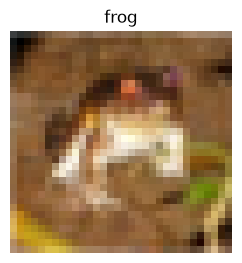

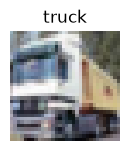

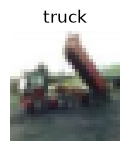

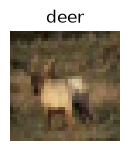

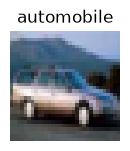

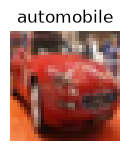

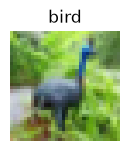

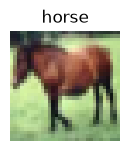

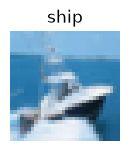

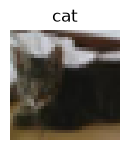

In [5]:
plt.figure(figsize=(12,6))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i])
    label=y_train[i][0]
    plt.title(class_names[label])
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    

In [6]:
from sklearn.model_selection import train_test_split
x_train,x_val,y_train,y_val=train_test_split(x_train,y_train,test_size=0.10,random_state=42,stratify=y_train.flatten())

In [7]:
print("Training images:",x_train.shape)
print("Training labels:",y_train.shape)

print("Validation images:",x_val.shape)
print("Validation labels:",y_val.shape)

print("Testing images:",x_test.shape)
print("Testing labels:",y_test.shape)

Training images: (45000, 32, 32, 3)
Training labels: (45000, 1)
Validation images: (5000, 32, 32, 3)
Validation labels: (5000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


In [8]:
pixel=[120,200,255]

x_train=x_train.astype('float32')/255.0
x_val=x_val.astype('float32')/255.0
x_test=x_test.astype('float32')/255.0

In [9]:
print("Training data")
print("Minimum pixel value:",x_train.min())
print("Maximum pixel value",x_train.max())

print("\n Validation")
print("Minimum pixel value:",x_val.min())
print("Maximum pixel value",x_val.max())

print("Testing data")
print("Minimum pixel value:",x_test.min())
print("Maximum pixel value",x_test.max())



Training data
Minimum pixel value: 0.0
Maximum pixel value 1.0

 Validation
Minimum pixel value: 0.0
Maximum pixel value 1.0
Testing data
Minimum pixel value: 0.0
Maximum pixel value 1.0


In [10]:
x_train_original=(x_train*255).astype('uint8')
x_val_original=(x_val*255).astype('uint8')
x_test_original=(x_test*255).astype('uint8')

In [11]:
x_train_minmax = x_train_original.astype('float32')/255.0
x_val_minmax = x_val_original.astype('float32')/255.0
x_test_minmax = x_test_original.astype('float32')/255.0

In [12]:
mean=x_train_original.astype('float32').mean(axis=(0,1,2))
std=x_train_original.astype('float32').std(axis=(0,1,2))

x_train_standard=(x_train_original.astype('float32')-mean)/std
x_val_standard=(x_val_original.astype('float32')-mean)/std
x_test_standard=(x_test_original.astype('float32')-mean)/std


In [13]:
print("Min-max normalization")

print("Minimum",x_train_minmax.min())
print("maximum",x_train_minmax.max())
print("mean",x_train_minmax.mean())

print("Standardization")
print("Minimum",x_train_standard.min())
print("Maximum",x_train_standard.max())
print("Mean",x_train_standard.mean())
print("standard Deviation",x_train_standard.std())

Min-max normalization
Minimum 0.0
maximum 1.0
mean 0.47323254
Standardization
Minimum -1.9894575
Maximum 2.1274548
Mean 2.3753978e-06
standard Deviation 0.9999989


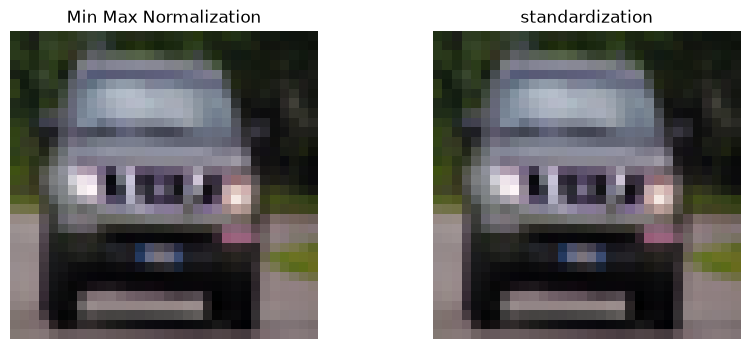

In [14]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(x_train_minmax[0])
plt.title("Min Max Normalization")
plt.axis("off")

plt.subplot(1,2,2)
img=(x_train_standard[0]*std+mean)/255.0

plt.imshow(np.clip(img,0,1))
plt.title("standardization")
plt.axis("off")
plt.show()

In [15]:
x_train_final=x_train_minmax
x_val_final=x_val_minmax
x_test_final=x_test_minmax

print("training",x_train_final.shape)
print("validation",x_val_final.shape)
print("testing",x_test_final.shape)

print("Minimum",x_train_final.min())
print("maximum",x_train_final.max())


training (45000, 32, 32, 3)
validation (5000, 32, 32, 3)
testing (10000, 32, 32, 3)
Minimum 0.0
maximum 1.0


question2

In [16]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D
from tensorflow.keras.layers import Flatten,Dense

In [17]:
model=Sequential()
model.add(tf.keras.Input(shape=(32,32,3)))
model.add(Conv2D(32,(3,3),activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Flatten())
model.add(Dense(128,activation='relu'))
model.add(Dense(10,activation='softmax'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [20]:
history = model.fit(x_train_final,y_train,epochs=10,batch_size=64,validation_data=(x_val_final,y_val))

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.4669 - loss: 1.4869 - val_accuracy: 0.5440 - val_loss: 1.2640
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5976 - loss: 1.1502 - val_accuracy: 0.6214 - val_loss: 1.0864
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6508 - loss: 1.0102 - val_accuracy: 0.6538 - val_loss: 1.0094
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6841 - loss: 0.9136 - val_accuracy: 0.6696 - val_loss: 0.9659
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7111 - loss: 0.8369 - val_accuracy: 0.6916 - val_loss: 0.9004
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.7332 - loss: 0.7677 - val_accuracy: 0.6770 - val_loss: 0.9387
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7552 - loss: 0.7051 - val_accuracy: 0.6920 - val_loss: 0.9232
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7770 - loss: 0.6454 - val_acc

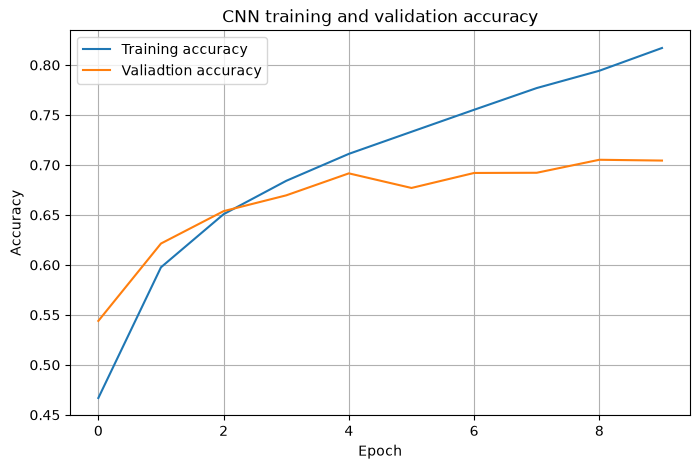

In [21]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'],label='Valiadtion accuracy')
plt.title("CNN training and validation accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

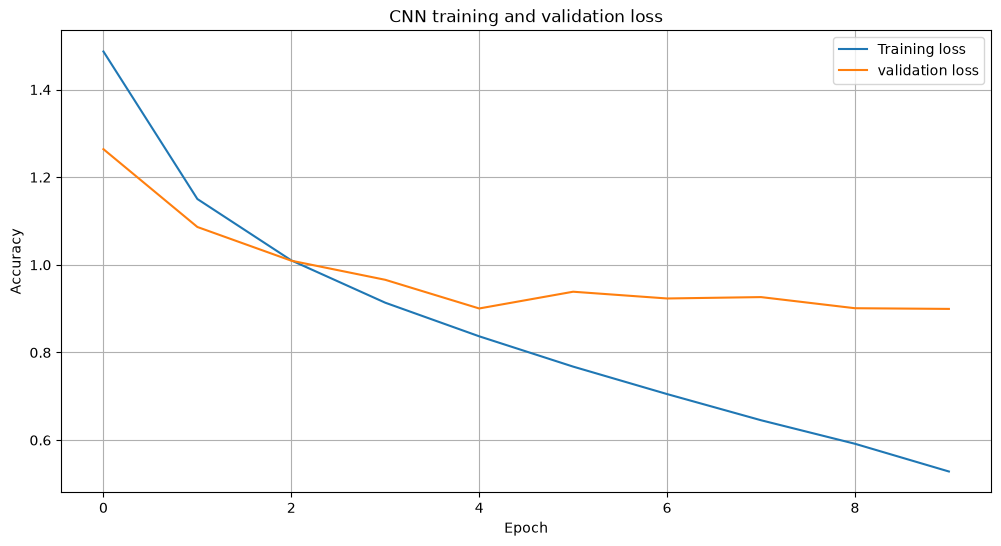

In [22]:
plt.figure(figsize=(12,6))
plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'],label='validation loss')

plt.title("CNN training and validation loss")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()


Question 3

In [24]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dense

model_3x3=Sequential([tf.keras.Input(shape=(32,32,3)),
            Conv2D(32,(3,3),activation='relu'),
            MaxPooling2D((2,2)),
            Conv2D(64,(3,3),activation='relu'),
            MaxPooling2D((2,2)),
            Flatten(),
            Dense(128,activation='relu'),
            Dense(10,activation='softmax')
                      ]) 

model_3x3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
model_5x5=Sequential([tf.keras.Input(shape=(32,32,3)),
            Conv2D(32,(5,5),activation='relu'),
            MaxPooling2D((2,2)),
            Conv2D(64,(5,5),activation='relu'),
            MaxPooling2D((2,2)),
            Flatten(),
            Dense(128,activation='relu'),
            Dense(10,activation='softmax')
                      ]) 
model_5x5.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 10, 10, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 259,914 (1015.29 KB)

 Trainable params: 259,914 (1015.29 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model_3x3.compile(optimizer='adam',loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model_5x5.compile(optimizer='adam',loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [27]:
import time
start=time.time()
history_3x3 = model_3x3.fit(x_train_final,y_train,epochs=10,batch_size=64,validation_data=(x_val_final,y_val))
time_3x3=time.time()-start
print('3x3 Training Time',time_3x3)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.4537 - loss: 1.5213 - val_accuracy: 0.5438 - val_loss: 1.2887
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.5867 - loss: 1.1713 - val_accuracy: 0.6104 - val_loss: 1.1098
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6427 - loss: 1.0162 - val_accuracy: 0.6448 - val_loss: 1.0238
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6802 - loss: 0.9190 - val_accuracy: 0.6724 - val_loss: 0.9748
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7076 - loss: 0.8387 - val_accuracy: 0.6714 - val_loss: 0.9841
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7321 - loss: 0.7679 - val_accuracy: 0.6724 - val_loss: 0.9594
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7573 - loss: 0.6968 - val_accuracy: 0.6996 - val_loss: 0.8863
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7757 - loss: 0.6393 - val_acc

In [28]:
import time
start=time.time()
history_5x5 = model_5x5.fit(x_train_final,y_train,epochs=10,batch_size=64,validation_data=(x_val_final,y_val))
time_5x5=time.time()-start
print('5x5 Training Time',time_5x5)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.4292 - loss: 1.5754 - val_accuracy: 0.5092 - val_loss: 1.3584
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.5630 - loss: 1.2354 - val_accuracy: 0.5710 - val_loss: 1.2281
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6152 - loss: 1.0947 - val_accuracy: 0.6200 - val_loss: 1.0860
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.6506 - loss: 0.9906 - val_accuracy: 0.6290 - val_loss: 1.0719
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.6810 - loss: 0.9093 - val_accuracy: 0.6484 - val_loss: 1.0081
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7048 - loss: 0.8456 - val_accuracy: 0.6666 - val_loss: 0.9684
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7227 - loss: 0.7929 - val_accuracy: 0.6616 - val_loss: 1.0144
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7371 - loss: 0.7449 - val_acc

In [29]:
accuracy_3x3=history_3x3.history['val_accuracy'][-1]
accuracy_5x5=history_5x5.history['val_accuracy'][-1]
print("3 by 3 validation accuracy",accuracy_3x3)
print("5 by 5 validation accracy",accuracy_5x5)
print("3 by 3 Training time",time_3x3)
print("5x5 Training time",time_5x5)

3 by 3 validation accuracy 0.7075999975204468
5 by 5 validation accracy 0.6690000295639038
3 by 3 Training time 81.0596022605896
5x5 Training time 85.91529321670532


Question 4

In [30]:

model_max=Sequential([tf.keras.Input(shape=(32,32,3)),
            Conv2D(32,(3,3),activation='relu'),
            MaxPooling2D(pool_size=(2,2)),
            Conv2D(64,(3,3),activation='relu'),
            MaxPooling2D(pool_size=(2,2)),
            Flatten(),
            Dense(128,activation='relu'),
            Dense(10,activation='softmax')
                      ]) 

model_max.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [31]:
from tensorflow.keras.layers import AveragePooling2D
model_avg=Sequential([tf.keras.Input(shape=(32,32,3)),
            Conv2D(32,(3,3),activation='relu'),
            AveragePooling2D(pool_size=(2,2)),
            Conv2D(64,(3,3),activation='relu'),
            AveragePooling2D(pool_size=(2,2)),
            Flatten(),
            Dense(128,activation='relu'),
            Dense(10,activation='softmax')
                      ]) 

model_avg.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 15, 15, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 6, 6, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
model_max.compile(optimizer='adam',loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model_avg.compile(optimizer='adam',loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [34]:
import time
start=time.time()
history_max = model_max.fit(x_train_final,y_train,epochs=10,batch_size=64,validation_data=(x_val_final,y_val))
time_max=time.time()-start
print('Max Polling Training Time',time_max)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.4507 - loss: 1.5286 - val_accuracy: 0.5606 - val_loss: 1.2634
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.6001 - loss: 1.1437 - val_accuracy: 0.6194 - val_loss: 1.0909
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.6495 - loss: 1.0000 - val_accuracy: 0.6488 - val_loss: 1.0097
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6831 - loss: 0.9080 - val_accuracy: 0.6632 - val_loss: 0.9744
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7112 - loss: 0.8287 - val_accuracy: 0.6806 - val_loss: 0.9081
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7340 - loss: 0.7673 - val_accuracy: 0.6950 - val_loss: 0.8926
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7552 - loss: 0.7063 - val_accuracy: 0.7028 - val_loss: 0.8729
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7741 - loss: 0.6499 - val_acc

In [35]:
import time
start=time.time()
history_avg = model_avg.fit(x_train_final,y_train,epochs=10,batch_size=64,validation_data=(x_val_final,y_val))
time_avg=time.time()-start
print('Average Polling Training Time',time_avg)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.4201 - loss: 1.6053 - val_accuracy: 0.4918 - val_loss: 1.4167
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.5418 - loss: 1.2865 - val_accuracy: 0.5838 - val_loss: 1.2116
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5916 - loss: 1.1572 - val_accuracy: 0.6040 - val_loss: 1.1376
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6339 - loss: 1.0469 - val_accuracy: 0.6414 - val_loss: 1.0377
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6608 - loss: 0.9709 - val_accuracy: 0.6600 - val_loss: 0.9884
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.6843 - loss: 0.9005 - val_accuracy: 0.6604 - val_loss: 0.9961
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7051 - loss: 0.8465 - val_accuracy: 0.6438 - val_loss: 1.0192
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7224 - loss: 0.7960 - val_acc

In [36]:

print("Max pooling validation accuracy",history_max.history['val_accuracy'][-1])

print("Average pooling validation accuracy",history_avg.history['val_accuracy'][-1])

print("max pooling validation loss",history_max.history['val_loss'][-1])

print("Average pooling validation loss",history_avg.history['val_loss'][-1])


Max pooling validation accuracy 0.7044000029563904
Average pooling validation accuracy 0.6908000111579895
max pooling validation loss 0.8908401131629944
Average pooling validation loss 0.923995316028595


In [37]:
import pandas as pd
pooling_results=pd.DataFrame({'Pooling method':['Max Pooling','Average Pooling'],'Validation Accuracy':[history_max.history['val_accuracy'][-1],history_avg.history['val_accuracy'][-1]],
                              'validation loss':[history_max.history['val_loss'][-1],history_avg.history['val_loss'][-1]],
                              'Training time9seconds)':[time_max,time_avg]})
                             
                             
print(pooling_results)

    Pooling method  Validation Accuracy  validation loss  \
0      Max Pooling               0.7044         0.890840   
1  Average Pooling               0.6908         0.923995   

   Training time9seconds)  
0               84.782117  
1               83.764943  


Question 5

In [38]:
model_shallow=Sequential([tf.keras.Input(shape=(32,32,3)),
            Conv2D(32,(3,3),activation='relu'),
            MaxPooling2D((2,2)),
            Conv2D(64,(3,3),activation='relu'),
            MaxPooling2D((2,2)),
            Flatten(),
            Dense(128,activation='relu'),
            Dense(10,activation='softmax')
                      ]) 
model_shallow.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
model_deep=Sequential([tf.keras.Input(shape=(32,32,3)),
            Conv2D(32,(3,3),activation='relu'),
            MaxPooling2D((2,2)),
            Conv2D(64,(3,3),activation='relu'),
            Conv2D(64,(3,3),activation='relu'),
            MaxPooling2D((2,2)),
            
            Conv2D(128,(3,3),activation='relu'),
                        MaxPooling2D((2,2)),
            Flatten(),
            Dense(128,activation='relu'),
            Dense(10,activation='softmax')
                      ]) 
model_deep.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 11, 11, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 147,978 (578.04 KB)

 Trainable params: 147,978 (578.04 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
model_shallow.compile(optimizer='adam',loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model_deep.compile(optimizer='adam',loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [41]:
import time
start=time.time()
history_shallow = model_shallow.fit(x_train_final,y_train,epochs=10,batch_size=64,validation_data=(x_val_final,y_val))
time_shallow=time.time()-start
print('Shallow CNN Training Time',time_shallow)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.4651 - loss: 1.4819 - val_accuracy: 0.5758 - val_loss: 1.2022
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6080 - loss: 1.1163 - val_accuracy: 0.6330 - val_loss: 1.0409
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6579 - loss: 0.9846 - val_accuracy: 0.6572 - val_loss: 0.9872
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6902 - loss: 0.8881 - val_accuracy: 0.6884 - val_loss: 0.9144
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7186 - loss: 0.8114 - val_accuracy: 0.6982 - val_loss: 0.8839
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7393 - loss: 0.7482 - val_accuracy: 0.6848 - val_loss: 0.9340
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7622 - loss: 0.6828 - val_accuracy: 0.7006 - val_loss: 0.8671
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7812 - loss: 0.6262 - val_accu

In [42]:
import time
start=time.time()
history_deep = model_deep.fit(x_train_final,y_train,epochs=10,batch_size=64,validation_data=(x_val_final,y_val))
time_deep=time.time()-start
print('Deep CNN Training Time',time_deep)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.3783 - loss: 1.6797 - val_accuracy: 0.4680 - val_loss: 1.4734
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.5327 - loss: 1.3073 - val_accuracy: 0.5562 - val_loss: 1.2586
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.5929 - loss: 1.1526 - val_accuracy: 0.6078 - val_loss: 1.0992
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.6311 - loss: 1.0474 - val_accuracy: 0.6308 - val_loss: 1.0505
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.6632 - loss: 0.9633 - val_accuracy: 0.6440 - val_loss: 1.0175
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.6834 - loss: 0.9032 - val_accuracy: 0.6676 - val_loss: 0.9654
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.7071 - loss: 0.8349 - val_accuracy: 0.6744 - val_loss: 0.9359
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.7256 - loss: 0.7801 - 

In [43]:
depth_results=pd.DataFrame({'Model':['Shallow CNN','Deep CNN'],'Training Accuracy':[
    history_shallow.history['accuracy'][-1],
    history_deep.history['accuracy'][-1]
],
'Validation Accuracy':[
    history_shallow.history['val_accuracy'][-1],
    history_deep.history['val_accuracy'][-1]
],
'Training loss':[
    history_shallow.history['loss'][-1],
    history_deep.history['loss'][-1]
],
'Validation Loss':[
    history_shallow.history['val_loss'][-1],
    history_deep.history['val_loss'][-1]
    
],
'Training Time(seconds)':[time_shallow,time_deep]
})

print(depth_results)

         Model  Training Accuracy  Validation Accuracy  Training loss  \
0  Shallow CNN           0.822400               0.7060       0.512211   
1     Deep CNN           0.763267               0.6854       0.674390   

   Validation Loss  Training Time(seconds)  
0         0.890211               80.419869  
1         0.945570              110.492524  


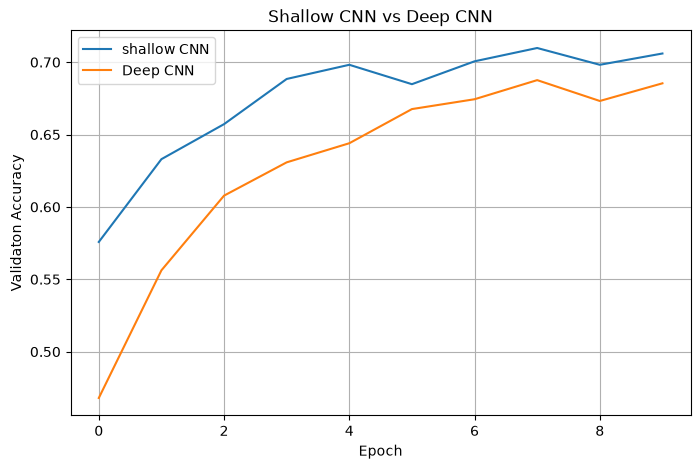

In [44]:
plt.figure(figsize=(8,5))
plt.plot(history_shallow.history['val_accuracy'], label='shallow CNN')

plt.plot(history_deep.history['val_accuracy'],label='Deep CNN')

plt.title('Shallow CNN vs Deep CNN')
plt.xlabel('Epoch')
plt.ylabel('Validaton Accuracy')
plt.legend()
plt.grid()
plt.show()

Question 6

In [45]:
from tensorflow.keras.layers import Dropout
model_dropout=Sequential([tf.keras.Input(shape=(32,32,3)),
            Conv2D(32,(3,3),activation='relu'),
            MaxPooling2D((2,2)),
            Conv2D(64,(3,3),activation='relu'),
            MaxPooling2D((2,2)),
        
            Flatten(),
            Dense(128,activation='relu'),
            Dropout(0.5),
            Dense(10,activation='softmax')
                      ]) 
model_dropout.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [46]:
from tensorflow.keras.regularizers import l2
model_l2=Sequential([tf.keras.Input(shape=(32,32,3)),
            Conv2D(32,(3,3),activation='relu',kernel_regularizer=l2(0.001)),
            MaxPooling2D((2,2)),
            Conv2D(64,(3,3),activation='relu',kernel_regularizer=l2(0.001)),
            MaxPooling2D((2,2)),
        
            Flatten(),
            Dense(128,activation='relu',kernel_regularizer=l2(0.001)),
            Dense(10,activation='softmax')
                      ]) 
model_l2.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_20 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [47]:
from tensorflow.keras.layers import(RandomFlip,RandomRotation,RandomZoom)

In [48]:
data_augmentation=Sequential([RandomFlip("horizontal"),RandomRotation(0.05),RandomZoom(0.1)])

In [49]:
model_augmentation = Sequential([
    tf.keras.Input(shape=(32, 32, 3)),

    data_augmentation,

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model_augmentation.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_10 (Sequential)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [50]:
models={
    'Dropout':model_dropout,
    'L2 regularization':model_l2,
    'Data Augmentation':model_augmentation
}
for name,model in models.items():
    model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [51]:
import time
histories={}
training_times={}
for name,model in models.items():
    print("\n Training:",name)
start=time.time()
history= model.fit(x_train_final,y_train,epochs=10,batch_size=64,validation_data=(x_val_final,y_val))
training_times[name]=time.time()-start
histories[name]=history
print(name,"Training completed")



 Training: Dropout

 Training: L2 regularization

 Training: Data Augmentation
Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.4260 - loss: 1.5801 - val_accuracy: 0.4844 - val_loss: 1.4098
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.5450 - loss: 1.2802 - val_accuracy: 0.5626 - val_loss: 1.2255
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.5881 - loss: 1.1624 - val_accuracy: 0.6352 - val_loss: 1.0544
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.6221 - loss: 1.0771 - val_accuracy: 0.6250 - val_loss: 1.1155
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.6408 - loss: 1.0215 - val_accuracy: 0.6426 - val_loss: 1.0398
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.6569 - loss: 0.9812 - val_accuracy: 0.6570 - val_loss: 1.0087
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.6683 - loss: 0.9506 - val_accuracy: 0.6824 - val_loss: 0.9223
Epoch 8/10
7

In [52]:
print("Models:", models.keys())
print("Histories:", histories.keys())

Models: dict_keys(['Dropout', 'L2 regularization', 'Data Augmentation'])
Histories: dict_keys(['Data Augmentation'])


In [53]:
print("Trained models:", list(histories.keys()))

Trained models: ['Data Augmentation']


In [55]:
import time

for name in ['Dropout', 'L2 regularization']:

    print("\nTraining:", name)

    start = time.time()

    history = models[name].fit(
        x_train_final,
        y_train,
        epochs=10,
        batch_size=64,
        validation_data=(x_val_final, y_val)
    )

    training_times[name] = time.time() - start
    histories[name] = history

    print(name, "training completed!")


Training: Dropout
Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.6864 - loss: 0.8866 - val_accuracy: 0.7012 - val_loss: 0.8710
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6935 - loss: 0.8634 - val_accuracy: 0.6968 - val_loss: 0.8794
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7023 - loss: 0.8346 - val_accuracy: 0.6844 - val_loss: 0.9122
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7093 - loss: 0.8202 - val_accuracy: 0.7024 - val_loss: 0.8582
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7157 - loss: 0.7920 - val_accuracy: 0.7066 - val_loss: 0.8716
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7228 - loss: 0.7785 - val_accuracy: 0.7054 - val_loss: 0.8793
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7307 - loss: 0.7520 - val_accuracy: 0.7080 - val_loss: 0.8492
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7353 - loss

In [56]:
regularization_results=pd.DataFrame({'Model':list(models.keys()),'Training Accuracy':[
    histories[name].history['accuracy'][-1]
    for name in models
],
'Validation Accuracy':[
    histories[name].history['val_accuracy'][-1]
    for name in models
],
'Training loss':[
    histories[name].history['loss'][-1]
    for name in models
],
'Validation Loss':[
    histories[name].history['val_loss'][-1]
    for name in models
    
]

})

print(regularization_results)

               Model  Training Accuracy  Validation Accuracy  Training loss  \
0            Dropout           0.743600               0.7112       0.709811   
1  L2 regularization           0.790156               0.7146       0.856871   
2  Data Augmentation           0.696422               0.6886       0.870195   

   Validation Loss  
0         0.864706  
1         1.071327  
2         0.918069  


Question 7

In [57]:
test_loss,test_accuracy=model.evaluate(x_test_final,y_test)
print("test loss",test_loss)
print("Test Accuracy",test_accuracy)
print("test Accuracy(%)",test_accuracy*100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6907 - loss: 0.9156
test loss 0.9155917167663574
Test Accuracy 0.6906999945640564
test Accuracy(%) 69.06999945640564


In [58]:
y_pred_prob=model.predict(x_test_final)
y_pred=np.argmax(y_pred_prob,axis=1)
y_true=y_test.flatten()
print("Actual labels",y_true[:10])
print("Predicted labels",y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Actual labels [3 8 8 0 6 6 1 6 3 1]
Predicted labels [3 8 1 0 4 6 1 6 3 1]


In [59]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Text(0.5, 58.38563368055553, 'Predicted Class')

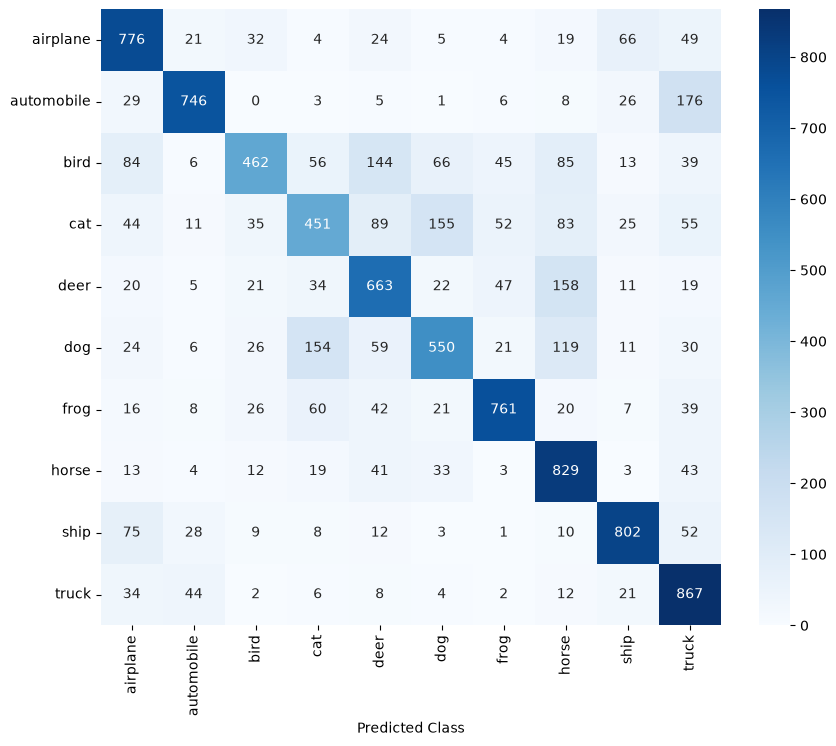

In [60]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm=confusion_matrix(y_true,y_pred)
plt.figure(figsize=(10,8))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=class_names,yticklabels=class_names)
plt.xlabel("Predicted Class")

In [61]:
from sklearn.metrics import classification_report
print(classification_report(y_true,y_pred,target_names=class_names))

              precision    recall  f1-score   support

    airplane       0.70      0.78      0.73      1000
  automobile       0.85      0.75      0.79      1000
        bird       0.74      0.46      0.57      1000
         cat       0.57      0.45      0.50      1000
        deer       0.61      0.66      0.64      1000
         dog       0.64      0.55      0.59      1000
        frog       0.81      0.76      0.78      1000
       horse       0.62      0.83      0.71      1000
        ship       0.81      0.80      0.81      1000
       truck       0.63      0.87      0.73      1000

    accuracy                           0.69     10000
   macro avg       0.70      0.69      0.69     10000
weighted avg       0.70      0.69      0.69     10000



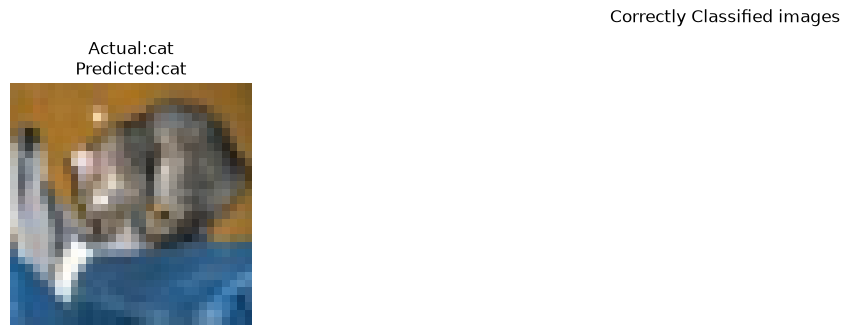

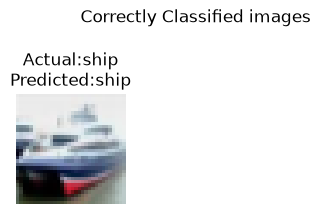

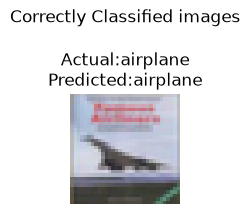

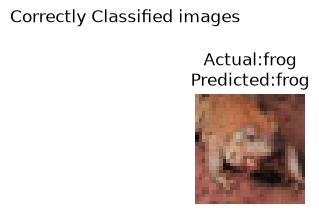

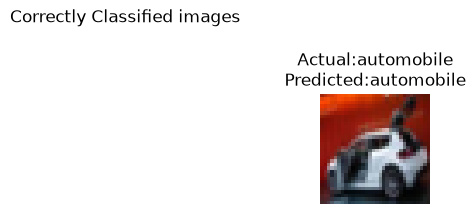

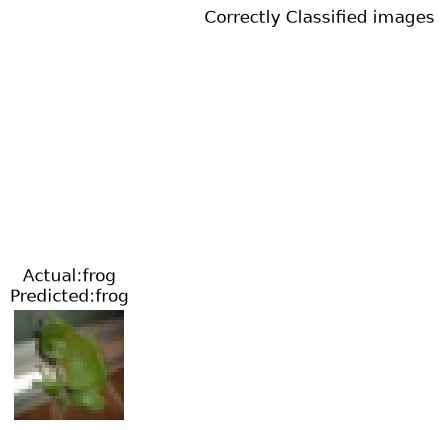

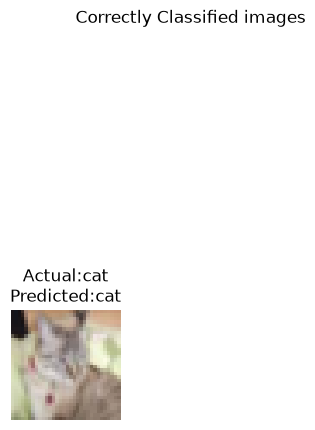

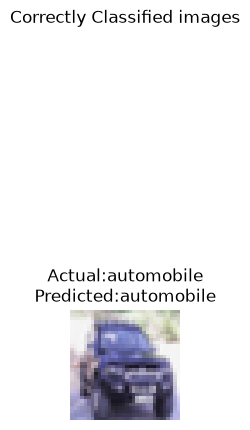

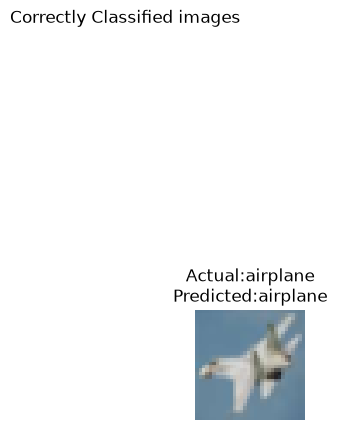

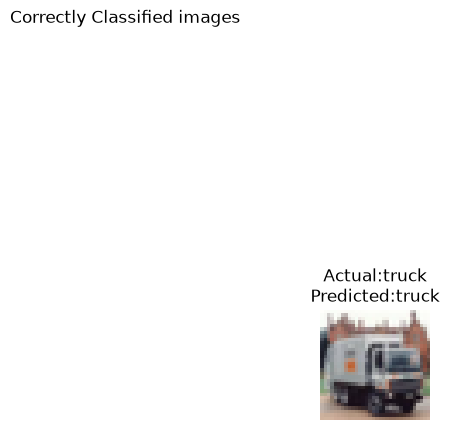

In [62]:
correct_indices=np.where(y_true==y_pred)[0]
plt.figure(figsize=(15,6))
for i in range(10):
    idx=correct_indices[i]
    plt.subplot(2,5,i+1)
    plt.imshow(x_test_original[idx])
    plt.title(f"Actual:{class_names[y_true[idx]]}\n"
              f"Predicted:{class_names[y_pred[idx]]}")
    plt.axis('off')
    plt.suptitle("Correctly Classified images")
    plt.tight_layout()
    plt.show()


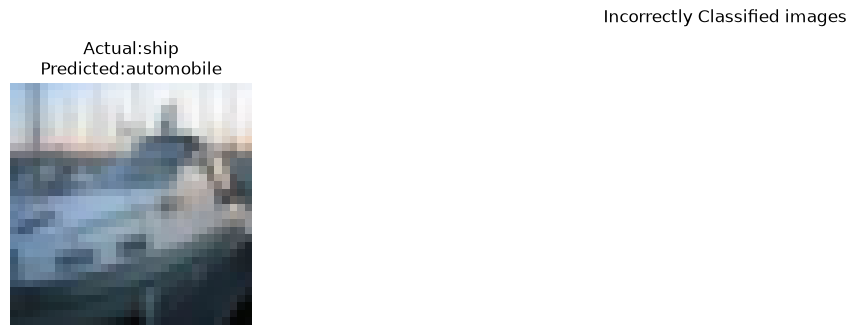

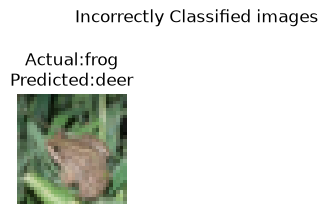

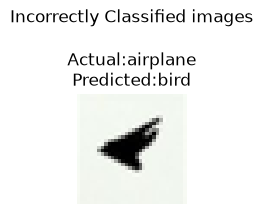

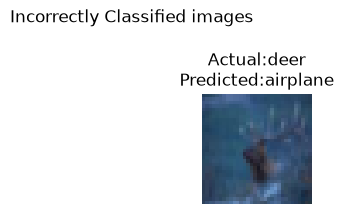

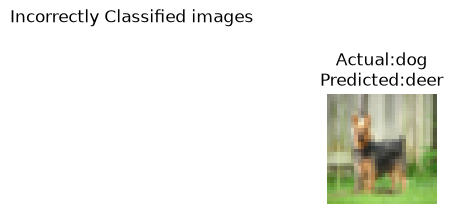

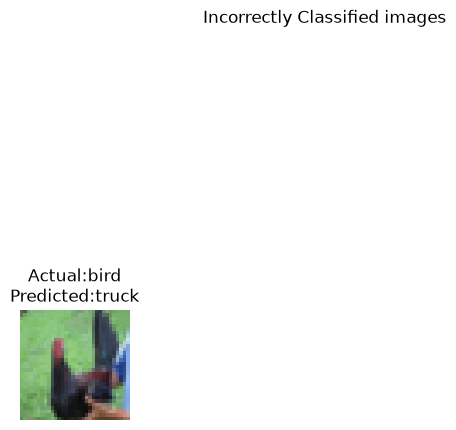

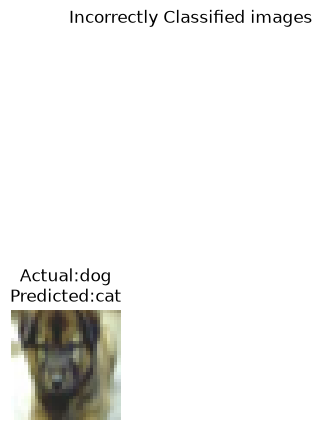

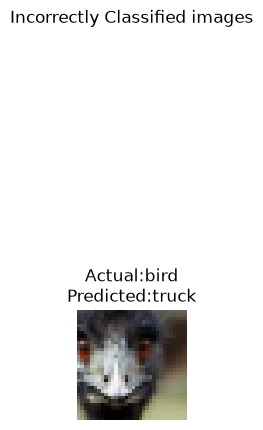

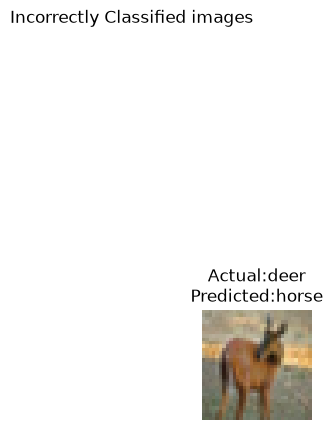

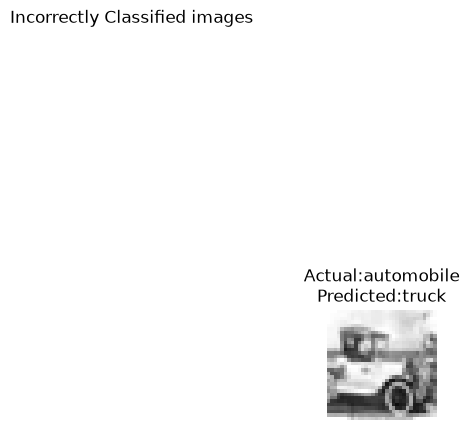

In [65]:
incorrect_indices=np.where(y_true!=y_pred)[0]
plt.figure(figsize=(15,6))
for i in range(10):
    idx=incorrect_indices[i]
    plt.subplot(2,5,i+1)
    plt.imshow(x_test_original[idx])
    plt.title(f"Actual:{class_names[y_true[idx]]}\n"
              f"Predicted:{class_names[y_pred[idx]]}")
    plt.axis('off')
    plt.suptitle("Incorrectly Classified images")
    plt.tight_layout()
    plt.show()


In [67]:
confidence=np.max(y_pred_prob,axis=1)*100
for i in range(10):
    print(f"Actual:{class_names[y_true[i]]:12}|"
          f"Predicted:{class_names[y_pred[i]]:12}|"
          f"Confidence:{confidence[i]:.2f}%")

Actual:cat         |Predicted:cat         |Confidence:48.83%
Actual:ship        |Predicted:ship        |Confidence:94.18%
Actual:ship        |Predicted:automobile  |Confidence:42.01%
Actual:airplane    |Predicted:airplane    |Confidence:86.62%
Actual:frog        |Predicted:deer        |Confidence:61.28%
Actual:frog        |Predicted:frog        |Confidence:84.17%
Actual:automobile  |Predicted:automobile  |Confidence:91.63%
Actual:frog        |Predicted:frog        |Confidence:47.54%
Actual:cat         |Predicted:cat         |Confidence:57.79%
Actual:automobile  |Predicted:automobile  |Confidence:83.27%


In [68]:
total_correct=len(correct_indices)
total_incorrect=len(incorrect_indices)
print("total test images:",len(y_true))
print("Correct Predictions:",total_correct)
print("Incorrect Predictions",total_incorrect)

print("Correct Percentage:",total_correct/len(y_true)*100)
print("Incorrect Percentage:",total_incorrect/len(y_true)*100)

total test images: 10000
Correct Predictions: 6907
Incorrect Predictions 3093
Correct Percentage: 69.07
Incorrect Percentage: 30.930000000000003


In [69]:
from sklearn.metrics import accuracy_score
class_accuracy={}
for i,class_name in enumerate(class_names):
    indices=np.where(y_true==i)[0]
    accuracy=accuracy_score(y_true[indices],y_pred[indices])*100
    class_accuracy[class_name]=accuracy
for class_name,accuracy in class_accuracy.items():
    print(f"{class_name}:{accuracy:2f}%")

airplane:77.600000%
automobile:74.600000%
bird:46.200000%
cat:45.100000%
deer:66.300000%
dog:55.000000%
frog:76.100000%
horse:82.900000%
ship:80.200000%
truck:86.700000%


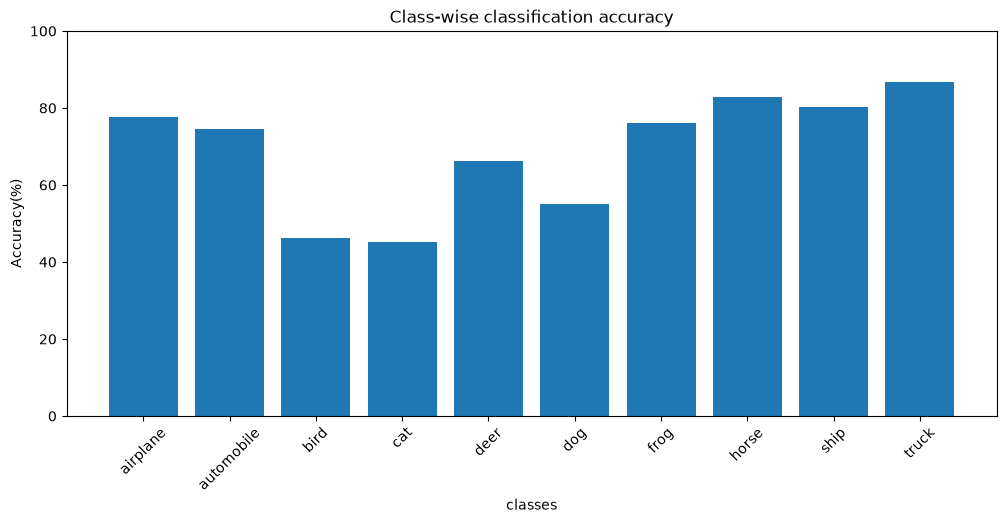

In [70]:
plt.figure(figsize=(12,5))
plt.bar(class_accuracy.keys(),class_accuracy.values())
plt.xlabel("classes")
plt.ylabel("Accuracy(%)")
plt.title("Class-wise classification accuracy")
plt.xticks(rotation=45)
plt.ylim(0,100)
plt.show()

Question 8


In [71]:
variables_to_check = [
    'model',
    'model_3x3',
    'model_5x5',
    'model_max',
    'model_avg',
    'model_shallow',
    'model_deep',
    'model_dropout',
    'model_l2',
    'model_augmentation',
    'history',
    'history_max',
    'history_avg'
]

for variable in variables_to_check:
    if variable in globals():
        print(variable, " : Available")
    else:
        print(variable, " : Not available")

model  : Available
model_3x3  : Available
model_5x5  : Available
model_max  : Available
model_avg  : Available
model_shallow  : Available
model_deep  : Available
model_dropout  : Available
model_l2  : Available
model_augmentation  : Available
history  : Available
history_max  : Available
history_avg  : Available


In [72]:

histories = {
    "Baseline CNN": history,
    "3x3 Kernel": history_3x3 if 'history_3x3' in globals() else None,
    "5x5 Kernel": history_5x5 if 'history_5x5' in globals() else None,
    "Max Pooling": history_max,
    "Average Pooling": history_avg,
    "Shallow CNN": history_shallow if 'history_shallow' in globals() else None,
    "Deep CNN": history_deep if 'history_deep' in globals() else None,
    "Dropout": history_dropout if 'history_dropout' in globals() else None,
    "L2 Regularization": history_l2 if 'history_l2' in globals() else None,
    "Data Augmentation": history_augmentation if 'history_augmentation' in globals() else None
}

for name, hist in histories.items():

    if hist is not None and hasattr(hist, 'history') and hist.history:
        print(name, ":", len(hist.history['loss']), "epochs completed")
    else:
        print(name, ": Training history not available")

Baseline CNN : 10 epochs completed
3x3 Kernel : 10 epochs completed
5x5 Kernel : 10 epochs completed
Max Pooling : 10 epochs completed
Average Pooling : 10 epochs completed
Shallow CNN : 10 epochs completed
Deep CNN : 10 epochs completed
Dropout : Training history not available
L2 Regularization : Training history not available
Data Augmentation : Training history not available


In [73]:
time_variables = [
    'time_3x3',
    'time_5x5',
    'time_max',
    'time_avg',
    'time_shallow',
    'time_deep',
    'time_dropout',
    'time_l2',
    'time_augmentation'
]

for variable in time_variables:
    if variable in globals():
        print(variable, ":", globals()[variable], "seconds")
    else:
        print(variable, ": Not available")

time_3x3 : 81.0596022605896 seconds
time_5x5 : 85.91529321670532 seconds
time_max : 84.78211665153503 seconds
time_avg : 83.76494336128235 seconds
time_shallow : 80.41986870765686 seconds
time_deep : 110.49252367019653 seconds
time_dropout : Not available
time_l2 : Not available
time_augmentation : Not available


In [74]:
import pandas as pd
models_to_compare = {
    "Baseline CNN": (model, history, None),
    "3x3 Kernel": (model_3x3, history_3x3, time_3x3),
    "5x5 Kernel": (model_5x5, history_5x5, time_5x5),
    "Max Pooling": (model_max, history_max, time_max),
    "Average Pooling": (model_avg, history_avg, time_avg),
    "Shallow CNN": (model_shallow, history_shallow, time_shallow),
    "Deep CNN": (model_deep, history_deep, time_deep)
}

results = []

for name, (cnn, hist, training_time) in models_to_compare.items():

    # Training and validation accuracy from the final epoch
    train_accuracy = hist.history['accuracy'][-1]
    val_accuracy = hist.history['val_accuracy'][-1]

    # Evaluate on test data
    test_loss, test_accuracy = cnn.evaluate(
        x_test_final, y_test, verbose=0
    )

    results.append({
        "Configuration": name,
        "Training Accuracy (%)": train_accuracy * 100,
        "Validation Accuracy (%)": val_accuracy * 100,
        "Test Accuracy (%)": test_accuracy * 100,
        "Training Time (seconds)": training_time
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.round(2)

comparison_df

,Configuration,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Training Time (seconds)
0,Baseline CNN,79.02,71.46,69.07,NaN
1,3x3 Kernel,81.91,70.76,69.50,81.06
2,5x5 Kernel,77.34,66.90,67.08,85.92
3,Max Pooling,81.08,70.44,69.25,84.78
4,Average Pooling,75.35,69.08,67.92,83.76
5,Shallow CNN,82.24,70.60,70.47,80.42
6,Deep CNN,76.33,68.54,68.17,110.49


In [77]:
import tensorflow as tf
import time
final_model=tf.keras.models.clone_model(model_shallow)
final_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
start_time=time.time()
final_history=final_model.fit(x_train_final,y_train,epochs=10,batch_size=64,validation_data=(x_val,y_val))

final_training_time=time.time()-start_time
print("Final model training time",round(final_training_time,2),"seconds")

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.4677 - loss: 1.4797 - val_accuracy: 0.5614 - val_loss: 1.2414
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6035 - loss: 1.1317 - val_accuracy: 0.6334 - val_loss: 1.0390
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6532 - loss: 0.9930 - val_accuracy: 0.6302 - val_loss: 1.0374
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6891 - loss: 0.8951 - val_accuracy: 0.6272 - val_loss: 1.0545
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7157 - loss: 0.8223 - val_accuracy: 0.6864 - val_loss: 0.9153
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7400 - loss: 0.7470 - val_accuracy: 0.6692 - val_loss: 0.9405
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7606 - loss: 0.6835 - val_accuracy: 0.6940 - val_loss: 0.8894
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7801 - loss: 0.6269 - val_acc

In [81]:
final_test_loss,final_test_accuracy=final_model.evaluate(x_test_final,y_test,verbose=1)

print("final_test Accuracy",round(final_test_accuracy * 100,2),"%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7122 - loss: 0.9208
final_test Accuracy 71.22 %


In [82]:
import os
image_folder="mobile_images"
for class_name in os.listdir(image_folder):
    class_path=os.path.join(image_folder,class_name)
    if os.path.isdir(class_path):
        images=os.listdir(class_path)
        print(class_name,":",len(images),"images")
    

automobile : 7 images
cat : 7 images
dog : 7 images


In [85]:
import os
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array
image_folder="mobile_images"
mobile_images=[]
actual_labels=[]
image_names=[]

for class_name in os.listdir(image_folder):
    class_path=os.path.join(image_folder,class_name)
    if os.path.isdir(class_path):
        for image_name in os.listdir(class_path):
            image_path=os.path.join(class_path,image_name)
            try:
                img=load_img(image_path,target_size=(32,32))
                img_array=img_to_array(img)
                mobile_images.append(img_array)
                actual_labels.append(class_name)
                image_names.append(image_name)
            except Exception as e:
                print("could not load",image_path,e)
mobile_images=np.array(mobile_images,dtype='float32')
mobile_images=mobile_images/255.0
actual_labels=np.array(actual_labels)

print("Mobile images shape",mobile_images.shape)
print("Actual labels shape",actual_labels.shape)
print("Minimum pixel value",mobile_images.min())
print("Maximum pixel value",mobile_images.max())

Mobile images shape (21, 32, 32, 3)
Actual labels shape (21,)
Minimum pixel value 0.0
Maximum pixel value 1.0


In [86]:
mobile_predictions=final_model.predict(mobile_images)
predicted_indices=np.argmax(mobile_predictions,axis=1)

predicted_labels=[class_names[i] for i in predicted_indices]
confidence_scores=(np.max(mobile_predictions,axis=1)*100)

mobile_results=pd.DataFrame({
    "Image Name":image_names,
    "Actual Class":actual_labels,
    "Predicted Class":predicted_labels,
    "Confidence(%)":confidence_scores.round(2)
})

mobile_results["Result"] = np.where(
    mobile_results["Actual Class"] ==
    mobile_results["Predicted Class"],
    "Correct",
    "Incorrect"
)

mobile_results

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step


,Image Name,Actual Class,Predicted Class,Confidence(%),Result
0,ip1.jpg,automobile,automobile,69.860001,Correct
1,ip2.jpg,automobile,automobile,97.360001,Correct
2,ip3.jpg,automobile,truck,99.930000,Incorrect
3,ip4.jpg,automobile,truck,98.489998,Incorrect
4,ip5.jpg,automobile,truck,99.849998,Incorrect
5,ip6.jpg,automobile,automobile,99.790001,Correct
6,ip7.jpg,automobile,truck,99.639999,Incorrect
7,image1.png,cat,cat,86.660004,Correct
8,image2.png,cat,dog,89.580002,Incorrect
9,images3.png,cat,frog,35.490002,Incorrect


In [87]:
correct_count = (mobile_results["Result"] == "Correct").sum()
incorrect_count = (mobile_results["Result"] == "Incorrect").sum()

mobile_accuracy = (correct_count / len(mobile_results)) * 100

print("Total Mobile Images:", len(mobile_results))
print("Correct Predictions:", correct_count)
print("Incorrect Predictions:", incorrect_count)
print("Real-World Accuracy:", round(mobile_accuracy, 2), "%")

Total Mobile Images: 21
Correct Predictions: 6
Incorrect Predictions: 15
Real-World Accuracy: 28.57 %


In [88]:
comparison = pd.DataFrame({
    "Dataset": ["CIFAR-10 Test Set", "Mobile Images"],
    "Total Images": [len(y_test), len(mobile_results)],
    "Accuracy (%)": [
        final_test_accuracy * 100,
        mobile_accuracy
    ]
})

comparison

,Dataset,Total Images,Accuracy (%)
0,CIFAR-10 Test Set,10000,71.219999
1,Mobile Images,21,28.571429


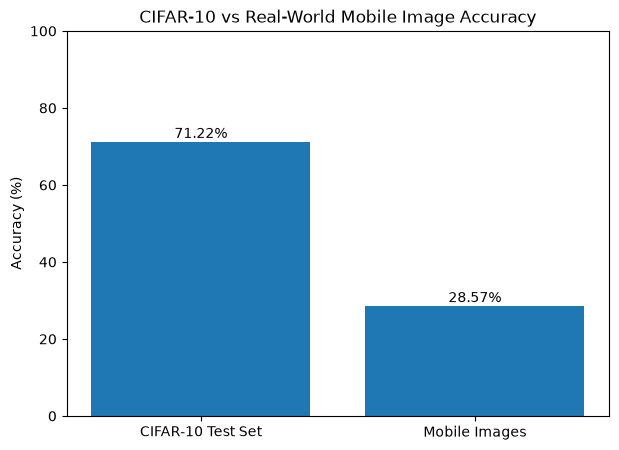

In [89]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    comparison["Dataset"],
    comparison["Accuracy (%)"]
)

plt.title("CIFAR-10 vs Real-World Mobile Image Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(comparison["Accuracy (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

In [96]:
lass_wise_results = mobile_results.groupby("Actual Class").agg(
    Total_Images=("Result", "count"),
    Correct_Predictions=("Result", lambda x: (x == "Correct").sum())
)

class_wise_results["Accuracy (%)"] = (
    class_wise_results["Correct_Predictions"] /
    class_wise_results["Total_Images"] * 100
)

class_wise_results.round(2)

,Total_Images,Correct_Predictions,Accuracy (%)
Actual Class,,,
automobile,7,3,42.86
cat,7,1,14.29
dog,7,2,28.57


In [100]:
print(mobile_results.columns.tolist())

['Image Name', 'Actual Class', 'Predicted Class', 'Confidence(%)', 'Result']


In [101]:
mobile_predictions = final_model.predict(mobile_images)

predicted_indices = np.argmax(mobile_predictions, axis=1)

predicted_labels = [
    class_names[i] for i in predicted_indices
]

confidence_scores = (
    np.max(mobile_predictions, axis=1) * 100
)

mobile_results = pd.DataFrame({
    "Image Name": image_names,
    "Actual Class": actual_labels,
    "Predicted Class": predicted_labels,
    "Confidence (%)": confidence_scores.round(2)
})

mobile_results["Result"] = np.where(
    mobile_results["Actual Class"] ==
    mobile_results["Predicted Class"],
    "Correct",
    "Incorrect"
)

display(mobile_results)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


,Image Name,Actual Class,Predicted Class,Confidence (%),Result
0,ip1.jpg,automobile,automobile,69.860001,Correct
1,ip2.jpg,automobile,automobile,97.360001,Correct
2,ip3.jpg,automobile,truck,99.930000,Incorrect
3,ip4.jpg,automobile,truck,98.489998,Incorrect
4,ip5.jpg,automobile,truck,99.849998,Incorrect
5,ip6.jpg,automobile,automobile,99.790001,Correct
6,ip7.jpg,automobile,truck,99.639999,Incorrect
7,image1.png,cat,cat,86.660004,Correct
8,image2.png,cat,dog,89.580002,Incorrect
9,images3.png,cat,frog,35.490002,Incorrect


In [102]:

total_images = len(mobile_results)

correct_count = (
    mobile_results["Result"] == "Correct"
).sum()

incorrect_count = (
    mobile_results["Result"] == "Incorrect"
).sum()

mobile_accuracy = (
    correct_count / total_images
) * 100

print("Total Images:", total_images)
print("Correct Predictions:", correct_count)
print("Incorrect Predictions:", incorrect_count)
print("Mobile Image Accuracy:", round(mobile_accuracy, 2), "%")

class_wise_results = mobile_results.groupby(
    "Actual Class"
).agg(
    Total_Images=("Result", "count"),
    Correct_Predictions=(
        "Result",
        lambda x: (x == "Correct").sum()
    )
)

class_wise_results["Accuracy (%)"] = (
    class_wise_results["Correct_Predictions"] /
    class_wise_results["Total_Images"]
) * 100

display(class_wise_results.round(2))

Total Images: 21
Correct Predictions: 6
Incorrect Predictions: 15
Mobile Image Accuracy: 28.57 %


,Total_Images,Correct_Predictions,Accuracy (%)
Actual Class,,,
automobile,7,3,42.86
cat,7,1,14.29
dog,7,2,28.57


,Dataset,Accuracy (%)
0,CIFAR-10 Test Dataset,71.22
1,Real-World Mobile Images,28.57


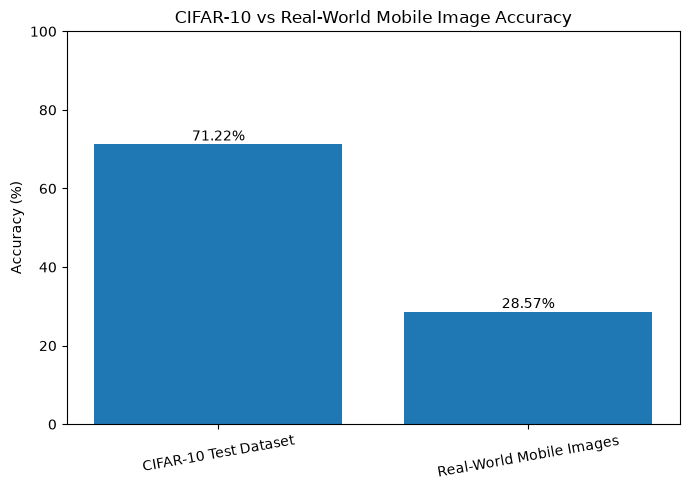

In [103]:
comparison_df = pd.DataFrame({
    "Dataset": [
        "CIFAR-10 Test Dataset",
        "Real-World Mobile Images"
    ],
    "Accuracy (%)": [
        final_test_accuracy * 100,
        mobile_accuracy
    ]
})

display(comparison_df.round(2))

plt.figure(figsize=(7, 5))

plt.bar(
    comparison_df["Dataset"],
    comparison_df["Accuracy (%)"]
)

plt.title("CIFAR-10 vs Real-World Mobile Image Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=10)

for i, value in enumerate(comparison_df["Accuracy (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [104]:
mobile_results.to_csv(
    "mobile_image_predictions.csv",
    index=False
)

print("Mobile prediction results saved successfully!")

Mobile prediction results saved successfully!
